<a href="https://colab.research.google.com/github/urvynous/UTS-Pemrograman-Big-Data/blob/main/52240032_MODUL_1_Praktikum_pyspark_rdd_databricks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MODUL PRAKTIKUM BIG DATA
## Pemrosesan Terdistribusi PySpark RDD di Databricks Community Edition

Memproses data besar (*Big Data*) menggunakan **PySpark RDD (Resilient Distributed Dataset)** di platform cloud **Databricks Community Edition**.

---

### 📌 Dataset yang Digunakan
* **Nama Dataset:** UCI / Kaggle – *Online Retail II Dataset*
* **Deskripsi:** Dataset transaksi nyata e-commerce ritel sebanyak lebih dari 500.000 baris record transaksi.
* **Tautan Dataset:**
  * **Kaggle:** [UCI Online Retail II Dataset](https://www.kaggle.com/datasets/vijayuv/onlineretail)

---

Nama: Siti Azkya Nurhalima

NIM: 52240032

## Setup PySpark & Dataset

In [ ]:
!pip install -q pyspark
from pyspark.sql import SparkSession
spark = SparkSession.builder.appName("RDD-Tugas-Mandiri").getOrCreate()
sc = spark.sparkContext
print("Versi PySpark:", spark.version, "| Master:", sc.master)

Versi PySpark: 4.0.5 | Master: local[*]


In [ ]:
from google.colab import drive
import os
drive.mount("/content/drive")

# Ubah path ini sesuai lokasi file di Drive kamu
DRIVE_PATH = "/content/drive/MyDrive/UTS_PEMROGRAMAN BIG DATA/online_retail.csv"
assert os.path.exists(DRIVE_PATH), f"File tidak ditemukan: {DRIVE_PATH}"

!mkdir -p /dbfs/FileStore/tables/
!cp "{DRIVE_PATH}" /dbfs/FileStore/tables/OnlineRetail.csv
!ls -l /dbfs/FileStore/tables/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
total 43984
-rw------- 1 root root 45038760 Nov 17 04:19 OnlineRetail.csv


## Baca Dataset -> RDD Tuple

In [ ]:
file_path = "/dbfs/FileStore/tables/OnlineRetail.csv"

df_raw = (spark.read.format("csv")
          .option("header", "true").option("inferSchema", "true")
          .option("encoding", "ISO-8859-1")
          .load(file_path))

# Samakan nama kolom (Online Retail I vs II)
rename = {"Invoice":"InvoiceNo", "Price":"UnitPrice", "Customer ID":"CustomerID"}
for old, new in rename.items():
    if old in df_raw.columns:
        df_raw = df_raw.withColumnRenamed(old, new)

df_clean = df_raw.dropna(subset=["InvoiceNo","CustomerID","UnitPrice","Quantity"])

# (InvoiceNo, StockCode, Description, Quantity, UnitPrice, CustomerID, Country)
rdd_raw = df_clean.rdd.map(lambda r: (
    str(r["InvoiceNo"]), str(r["StockCode"]), str(r["Description"]),
    int(r["Quantity"]), float(r["UnitPrice"]),
    str(int(float(r["CustomerID"]))), str(r["Country"])))

rdd = rdd_raw.repartition(8)
rdd_uk_valid = rdd.filter(lambda x: x[3] > 0 and x[4] > 0 and x[6] == "United Kingdom")
print(f"Total record bersih : {rdd.count():,}")
print(f"Transaksi valid UK  : {rdd_uk_valid.count():,}")

Total record bersih : 406,829
Transaksi valid UK  : 354,321


## Transformasi (filter & map)

In [ ]:
rdd_uk_valid = rdd.filter(lambda x: x[3] > 0 and x[4] > 0 and x[6] == "United Kingdom")
rdd_invoice_spent = rdd_uk_valid.map(lambda x: (x[0], round(x[3] * x[4], 2)))

print(f"Jumlah Transaksi Valid UK: {rdd_uk_valid.count():,}")
print("Contoh Pair RDD (InvoiceNo, TotalSpent):", rdd_invoice_spent.take(3))

Jumlah Transaksi Valid UK: 354,321
Contoh Pair RDD (InvoiceNo, TotalSpent): [('536373', 15.3), ('536373', 20.34), ('536373', 20.34)]


## Agregasi (reduceByKey & sorting)

In [ ]:
import time

start_time = time.time()
rdd_total_per_invoice = rdd_invoice_spent.reduceByKey(lambda a, b: a + b)
rdd_sorted_invoice = rdd_total_per_invoice.sortBy(lambda x: x[1], ascending=False)
top_10_invoices = rdd_sorted_invoice.take(10)
execution_time = time.time() - start_time

print(f"Waktu Eksekusi Agregasi RDD: {execution_time:.4f} detik\n")
print("--- TOP 10 INVOICE DENGAN TRANSAKSI TERBESAR ---")
for invoice, total in top_10_invoices:
    print(f"Invoice ID: {invoice:<10} | Total Belanja: £ {total:,.2f}")

Waktu Eksekusi Agregasi RDD: 4.3684 detik

--- TOP 10 INVOICE DENGAN TRANSAKSI TERBESAR ---
Invoice ID: 581483     | Total Belanja: £ 168,469.60
Invoice ID: 541431     | Total Belanja: £ 77,183.60
Invoice ID: 556444     | Total Belanja: £ 38,970.00
Invoice ID: 567423     | Total Belanja: £ 31,698.16
Invoice ID: 572209     | Total Belanja: £ 22,206.00
Invoice ID: 567381     | Total Belanja: £ 22,104.80
Invoice ID: 550461     | Total Belanja: £ 21,535.90
Invoice ID: 562439     | Total Belanja: £ 18,841.48
Invoice ID: 556255     | Total Belanja: £ 16,488.00
Invoice ID: 537659     | Total Belanja: £ 15,885.49


## Caching & Persistence

In [ ]:
from pyspark import StorageLevel

rdd_sorted_invoice.persist(StorageLevel.MEMORY_ONLY)

t0 = time.time()
count_1 = rdd_sorted_invoice.count()
t1 = time.time() - t0

t2 = time.time()
count_2 = rdd_sorted_invoice.count()
t3 = time.time() - t2

print(f"Eksekusi Aksi Pertama (Tanpa Cache Warmup) : {t1:.4f} detik")
print(f"Eksekusi Aksi Kedua (Menggunakan Cache)    : {t3:.4f} detik")

rdd_sorted_invoice.unpersist()

Eksekusi Aksi Pertama (Tanpa Cache Warmup) : 1.2163 detik
Eksekusi Aksi Kedua (Menggunakan Cache)    : 0.5907 detik


PythonRDD[37] at RDD at PythonRDD.scala:57

## Produk terlaris

In [ ]:
rdd_product_qty = (rdd_uk_valid.map(lambda x: (x[2], x[3]))
                   .reduceByKey(lambda a, b: a + b)
                   .sortBy(lambda x: x[1], ascending=False))

print("--- TOP 5 PRODUK TERLARIS ---")
for product, total_qty in rdd_product_qty.take(5):
    print(f"Produk: {product:<40} | Jumlah Terjual: {total_qty:,} unit")

--- TOP 5 PRODUK TERLARIS ---
Produk: PAPER CRAFT , LITTLE BIRDIE              | Jumlah Terjual: 80,995 unit
Produk: MEDIUM CERAMIC TOP STORAGE JAR           | Jumlah Terjual: 76,919 unit
Produk: WORLD WAR 2 GLIDERS ASSTD DESIGNS        | Jumlah Terjual: 49,182 unit
Produk: JUMBO BAG RED RETROSPOT                  | Jumlah Terjual: 41,981 unit
Produk: WHITE HANGING HEART T-LIGHT HOLDER       | Jumlah Terjual: 34,648 unit


## Tugas Mandiri

### Kategori A: Business Intelligence

In [ ]:
print("=== TUGAS A1: Top 5 Pelanggan Luar Negeri (Non-UK) ===")
rdd_non_uk = rdd.filter(lambda x: x[6] != "United Kingdom" and x[3] > 0 and x[4] > 0)
rdd_cust_spent = rdd_non_uk.map(lambda x: (x[5], x[3] * x[4]))
top5_non_uk = (rdd_cust_spent.reduceByKey(lambda a, b: a + b)
               .sortBy(lambda x: x[1], ascending=False).take(5))
for cust, total in top5_non_uk:
    print(f"Customer ID: {cust:<8} | Total Belanja: £ {total:,.2f}")

=== TUGAS A1: Top 5 Pelanggan Luar Negeri (Non-UK) ===
Customer ID: 14646    | Total Belanja: £ 280,206.02
Customer ID: 14911    | Total Belanja: £ 143,825.06
Customer ID: 12415    | Total Belanja: £ 124,914.53
Customer ID: 14156    | Total Belanja: £ 117,379.63
Customer ID: 17404    | Total Belanja: £ 31,906.82


**Interpretasi A1:** Lima pelanggan luar negeri terbesar menyumbang total £698.232. Pelanggan teratas (ID 14646, £280.206) belanjanya hampir 2x lipat pelanggan kedua (ID 14911, £143.825) dan sekitar 9x pelanggan kelima (ID 17404, £31.907). Empat pelanggan teratas semuanya di atas £100.000, lalu turun tajam di posisi kelima. Artinya pendapatan luar negeri sangat terkonsentrasi pada segelintir pelanggan, kemungkinan besar pembeli grosir/reseller, sehingga mempertahankan mereka lebih penting daripada menambah pelanggan kecil.

In [ ]:
print("=== TUGAS A2: Potensi Kerugian Transaksi Pembatalan ===")
# Pembatalan = InvoiceNo diawali huruf 'C'
rdd_cancel = rdd.filter(lambda x: x[0].startswith("C"))
n_cancel_rows    = rdd_cancel.count()
n_cancel_invoice = rdd_cancel.map(lambda x: x[0]).distinct().count()
total_loss = rdd_cancel.map(lambda x: abs(x[3] * x[4])).sum()
print(f"Jumlah baris transaksi dibatalkan : {n_cancel_rows:,}")
print(f"Jumlah invoice pembatalan (unik)  : {n_cancel_invoice:,}")
print(f"Total estimasi nilai kerugian     : £ {total_loss:,.2f}")

=== TUGAS A2: Potensi Kerugian Transaksi Pembatalan ===
Jumlah baris transaksi dibatalkan : 8,905
Jumlah invoice pembatalan (unik)  : 3,654
Total estimasi nilai kerugian     : £ 611,342.09


**Interpretasi A2:** Terdapat 8.905 baris transaksi pembatalan (sekitar 2,2% dari 406.829 record) yang berasal dari 3.654 invoice unik, atau rata-rata sekitar 2,4 item per invoice pembatalan. Estimasi nilai yang terdampak mencapai £611.342,09, kira-kira £167 per invoice pembatalan. Angka ini adalah batas atas kerugian karena dihitung dari nilai mutlak Quantity x UnitPrice; sebagian retur bisa saja diganti produk atau dijual ulang. Meski persentasenya kecil, nilainya besar sehingga perlu dianalisis penyebab retur (kualitas produk, salah kirim, dll).

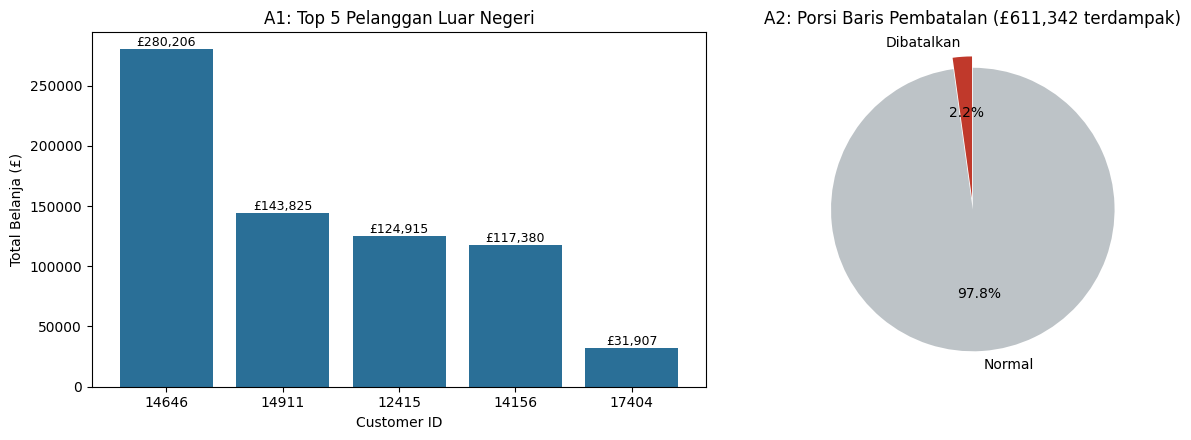

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# A1: Top 5 pelanggan non-UK
custs = [c for c, _ in top5_non_uk]
vals = [v for _, v in top5_non_uk]
ax[0].bar(custs, vals, color="#2a6f97")
ax[0].set_title("A1: Top 5 Pelanggan Luar Negeri")
ax[0].set_xlabel("Customer ID"); ax[0].set_ylabel("Total Belanja (£)")
for i, v in enumerate(vals):
    ax[0].text(i, v, f"£{v:,.0f}", ha="center", va="bottom", fontsize=9)

# A2: porsi transaksi pembatalan
total_rec = rdd.count()
ax[1].pie([n_cancel_rows, total_rec - n_cancel_rows],
          labels=["Dibatalkan", "Normal"], autopct="%1.1f%%",
          colors=["#c0392b", "#bdc3c7"], explode=(0.08, 0), startangle=90)
ax[1].set_title(f"A2: Porsi Baris Pembatalan (£{total_loss:,.0f} terdampak)")

plt.tight_layout(); plt.show()

### Kategori B: Performance Engineering

In [ ]:
import time
print("=== TUGAS B1: Pengaruh Jumlah Partisi ===")
rdd_invoice_spent = rdd_uk_valid.map(lambda x: (x[0], round(x[3] * x[4], 2)))
rdd_invoice_spent.cache(); rdd_invoice_spent.count()   # warmup agar adil

for n in [2, 8, 16]:
    rp = rdd_invoice_spent.repartition(n)
    rp.count()                                         # materialisasi shuffle repartition
    runs = []
    for _ in range(3):
        t = time.time()
        rp.reduceByKey(lambda a, b: a + b).count()
        runs.append(time.time() - t)
    print(f"{n:>2} partisi | rata-rata: {sum(runs)/3:.4f} detik | min: {min(runs):.4f} detik")

=== TUGAS B1: Pengaruh Jumlah Partisi ===
 2 partisi | rata-rata: 1.3076 detik | min: 0.8619 detik
 8 partisi | rata-rata: 1.3055 detik | min: 1.1837 detik
16 partisi | rata-rata: 2.6243 detik | min: 1.7642 detik


**Interpretasi B1:** Jumlah partisi yang lebih banyak tidak membuat lebih cepat. Waktu rata-rata 2 partisi (1,31 s) hampir sama dengan 8 partisi (1,31 s), sedangkan 16 partisi justru sekitar 2x lebih lambat (2,62 s). Penyebabnya, Spark berjalan di mode `local[*]` dengan jumlah core terbatas, sehingga partisi berlebih hanya menambah overhead penjadwalan task dan shuffle tanpa menambah paralelisme. Jumlah partisi sebaiknya disesuaikan dengan jumlah core/ukuran data (umumnya 2-4x jumlah core pada cluster nyata).

In [ ]:
print("=== TUGAS B2: reduceByKey vs groupByKey ===")
rdd_desc_qty = rdd_uk_valid.map(lambda x: (x[2], x[3]))
rdd_desc_qty.cache(); rdd_desc_qty.count()

def bench(fn, n=3):
    ts = []
    for _ in range(n):
        t = time.time(); fn(); ts.append(time.time() - t)
    return sum(ts) / n

t_rbk = bench(lambda: rdd_desc_qty.reduceByKey(lambda a, b: a + b).count())
t_gbk = bench(lambda: rdd_desc_qty.groupByKey().mapValues(sum).count())
print(f"reduceByKey()          : {t_rbk:.4f} detik")
print(f"groupByKey()+mapValues : {t_gbk:.4f} detik")
print(f"Selisih                : {abs(t_gbk - t_rbk):.4f} detik")

=== TUGAS B2: reduceByKey vs groupByKey ===
reduceByKey()          : 0.8873 detik
groupByKey()+mapValues : 1.0301 detik
Selisih                : 0.1428 detik


**Interpretasi B2:** `reduceByKey` (0,887 s) lebih cepat sekitar 0,14 detik atau 16% dibanding `groupByKey` + `mapValues(sum)` (1,030 s). Arahnya sesuai teori: `reduceByKey` menjumlahkan secara lokal di tiap partisi sebelum shuffle (map-side combine), sedangkan `groupByKey` mengirim seluruh nilai ke reducer lebih dulu. Selisihnya masih kecil karena data hanya ratusan ribu baris dan berjalan di satu mesin tanpa transfer jaringan; di cluster dengan data besar, selisihnya akan jauh lebih besar.

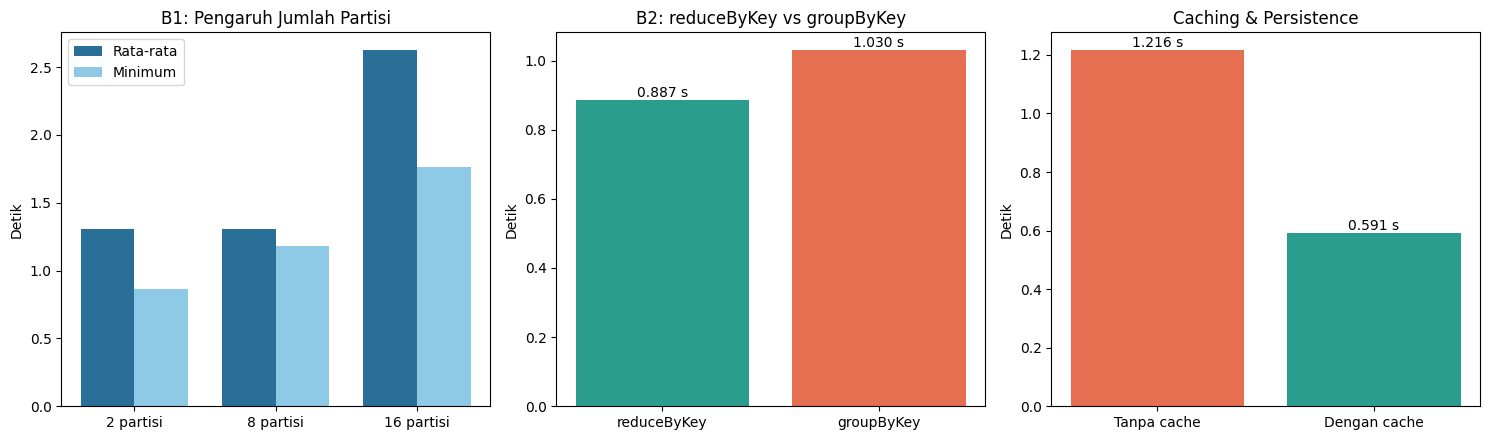

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))

# B1
parts = [2, 8, 16]
avg = [1.3076, 1.3055, 2.6243]
mn  = [0.8619, 1.1837, 1.7642]
x = range(3); w = 0.38
ax[0].bar([i - w/2 for i in x], avg, w, label="Rata-rata", color="#2a6f97")
ax[0].bar([i + w/2 for i in x], mn,  w, label="Minimum",  color="#8ecae6")
ax[0].set_xticks(list(x)); ax[0].set_xticklabels([f"{p} partisi" for p in parts])
ax[0].set_ylabel("Detik"); ax[0].set_title("B1: Pengaruh Jumlah Partisi"); ax[0].legend()

# B2
ax[1].bar(["reduceByKey", "groupByKey"], [0.8873, 1.0301], color=["#2a9d8f", "#e76f51"])
ax[1].set_ylabel("Detik"); ax[1].set_title("B2: reduceByKey vs groupByKey")
for i, v in enumerate([0.8873, 1.0301]):
    ax[1].text(i, v, f"{v:.3f} s", ha="center", va="bottom")

# Caching (bagian 6)
ax[2].bar(["Tanpa cache", "Dengan cache"], [1.2163, 0.5907], color=["#e76f51", "#2a9d8f"])
ax[2].set_ylabel("Detik"); ax[2].set_title("Caching & Persistence")
for i, v in enumerate([1.2163, 0.5907]):
    ax[2].text(i, v, f"{v:.3f} s", ha="center", va="bottom")

plt.tight_layout(); plt.show()

**Analisis:** `reduceByKey` melakukan *map-side combine* (menjumlahkan lokal di tiap partisi sebelum shuffle), sehingga data yang dikirim antar node lebih sedikit. `groupByKey` mengirim *semua* nilai ke reducer baru dijumlahkan. Pada data kecil / mode `local[*]` selisihnya tipis, tetapi di cluster dan data besar `reduceByKey` jauh lebih efisien dan hemat memori.

### Kategori C: String dan Waktu

In [ ]:
print("=== TUGAS C1: Jam Sibuk Transaksi ===")
# RDD utama tidak punya kolom tanggal -> buat RDD terpisah dari df_clean (rdd utama tidak diubah)
def extract_hour(row):
    v = row["InvoiceDate"]
    if hasattr(v, "hour"):
        return v.hour
    s = str(v)                       # "12/1/2010 8:26" atau "2010-12-01 08:26:00"
    if " " in s:
        return int(s.split(" ")[1].split(":")[0])
    return 0

# hitung per invoice unik agar 'transaksi' = invoice, bukan baris item
rdd_inv_hour = (df_clean.rdd.map(lambda r: (str(r["InvoiceNo"]), extract_hour(r)))
                .distinct())
rdd_peak = (rdd_inv_hour.map(lambda x: (x[1], 1))
            .reduceByKey(lambda a, b: a + b)
            .sortBy(lambda x: x[1], ascending=False))
print("Top 3 jam tersibuk (jumlah invoice unik):")
for h, f in rdd_peak.take(3):
    print(f"Jam {h:02d}:00 | {f:,} transaksi")

=== TUGAS C1: Jam Sibuk Transaksi ===
Top 3 jam tersibuk (jumlah invoice unik):
Jam 12:00 | 3,597 transaksi
Jam 13:00 | 3,043 transaksi
Jam 11:00 | 2,770 transaksi


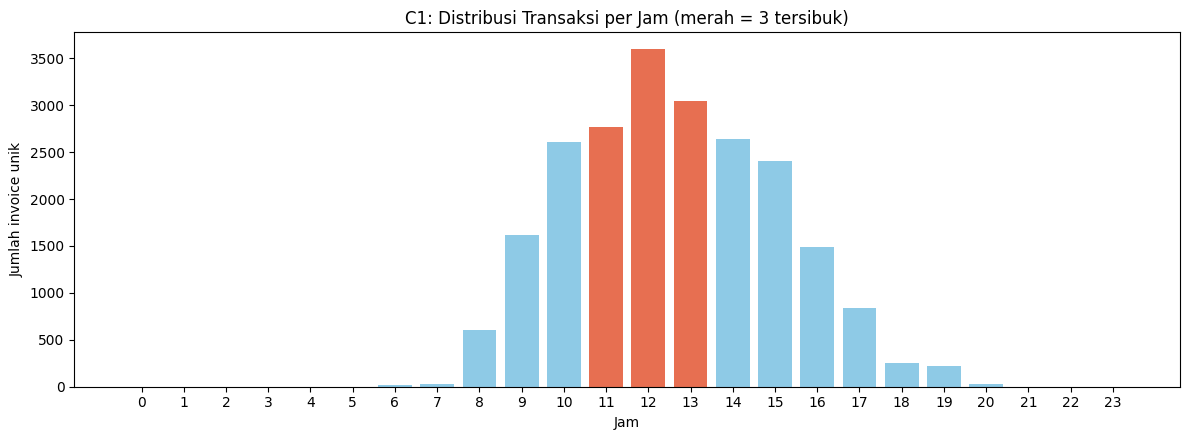

In [ ]:
data = dict(rdd_peak.collect())
top3 = [h for h, _ in rdd_peak.take(3)]
hours = list(range(24))
counts = [data.get(h, 0) for h in hours]
colors = ["#e76f51" if h in top3 else "#8ecae6" for h in hours]

plt.figure(figsize=(12, 4.5))
plt.bar(hours, counts, color=colors)
plt.xticks(hours)
plt.xlabel("Jam"); plt.ylabel("Jumlah invoice unik")
plt.title("C1: Distribusi Transaksi per Jam (merah = 3 tersibuk)")
plt.tight_layout(); plt.show()

**Interpretasi C1:** Transaksi paling ramai terjadi pada jam 12:00 (3.597 invoice), 13:00 (3.043), dan 11:00 (2.770), yaitu sekitar jam makan siang. Pola ini menunjukkan pelanggan (kemungkinan pembeli bisnis/reseller) paling aktif memesan di tengah hari, sehingga promosi, stok, dan kapasitas customer service sebaiknya difokuskan pada rentang 11:00-13:00. Catatan: penghitungan memakai invoice unik, bukan baris item, sehingga angkanya lebih kecil dan urutan ke-3 berbeda dibanding penghitungan per baris.

In [ ]:
print("=== TUGAS C2: Produk mengandung 'HEART' ===")
rdd_heart = rdd_uk_valid.filter(lambda x: "heart" in x[2].lower())
rdd_heart_avg = (rdd_heart.map(lambda x: (x[2], (x[4], 1)))
                 .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
                 .mapValues(lambda v: round(v[0] / v[1], 2)))
print(f"Total varian produk 'HEART': {rdd_heart_avg.count()}")
print("Contoh 5 produk & rata-rata harga:")
for p, a in rdd_heart_avg.take(5):
    print(f"- {p:<40} | £ {a:.2f}")

=== TUGAS C2: Produk mengandung 'HEART' ===
Total varian produk 'HEART': 297
Contoh 5 produk & rata-rata harga:
- RED WOOLLY HOTTIE WHITE HEART.           | £ 4.06
- HEART T-LIGHT HOLDER                     | £ 1.45
- FINE WICKER HEART                        | £ 1.24
- PINK HEART DOTS HOT WATER BOTTLE         | £ 3.75
- PINK LOVE HEART SHAPE CUP                | £ 0.88


**Interpretasi C2:** Ada 297 varian produk yang mengandung kata "HEART", menunjukkan tema hati adalah lini produk yang sangat beragam. Contoh yang tampil berharga murah (rata-rata £0,88-£4,06), yang cocok dengan kategori barang dekorasi/hadiah bernilai kecil. Rata-rata dihitung per baris transaksi (tanpa pembobotan kuantitas), dan kelima contoh diambil dengan `take(5)` sehingga bukan urutan tertentu.

### Kategori D: Set Operations

In [ ]:
print("=== TUGAS D1: Produk Eksklusif Germany vs France ===")
prod_de = rdd.filter(lambda x: x[6] == "Germany").map(lambda x: x[2]).distinct()
prod_fr = rdd.filter(lambda x: x[6] == "France").map(lambda x: x[2]).distinct()
excl = prod_de.subtract(prod_fr)
print(f"Produk eksklusif Germany (tidak pernah dibeli di France): {excl.count()}")
print("Contoh 5 produk:")
for p in excl.take(5):
    print(f"- {p}")

=== TUGAS D1: Produk Eksklusif Germany vs France ===
Produk eksklusif Germany (tidak pernah dibeli di France): 518
Contoh 5 produk:
- GINGHAM ROSE WRAP
- WHITE WOOD GARDEN PLANT LADDER
- TEA TIME KITCHEN APRON
- PINK CANDYSTUFT ARTIFICIAL FLOWER
- HAND WARMER OWL DESIGN


**Interpretasi D1:** Sebanyak 518 produk pernah dibeli di Germany tetapi tidak pernah di France. Ini menunjukkan perbedaan selera/katalog antar pasar dan bisa jadi peluang cross-selling ke pelanggan France. Namun hati-hati: "eksklusif" di sini bisa juga karena volume transaksi France lebih sedikit, dan pencocokan memakai nama deskripsi sehingga perbedaan ejaan dihitung sebagai produk berbeda.

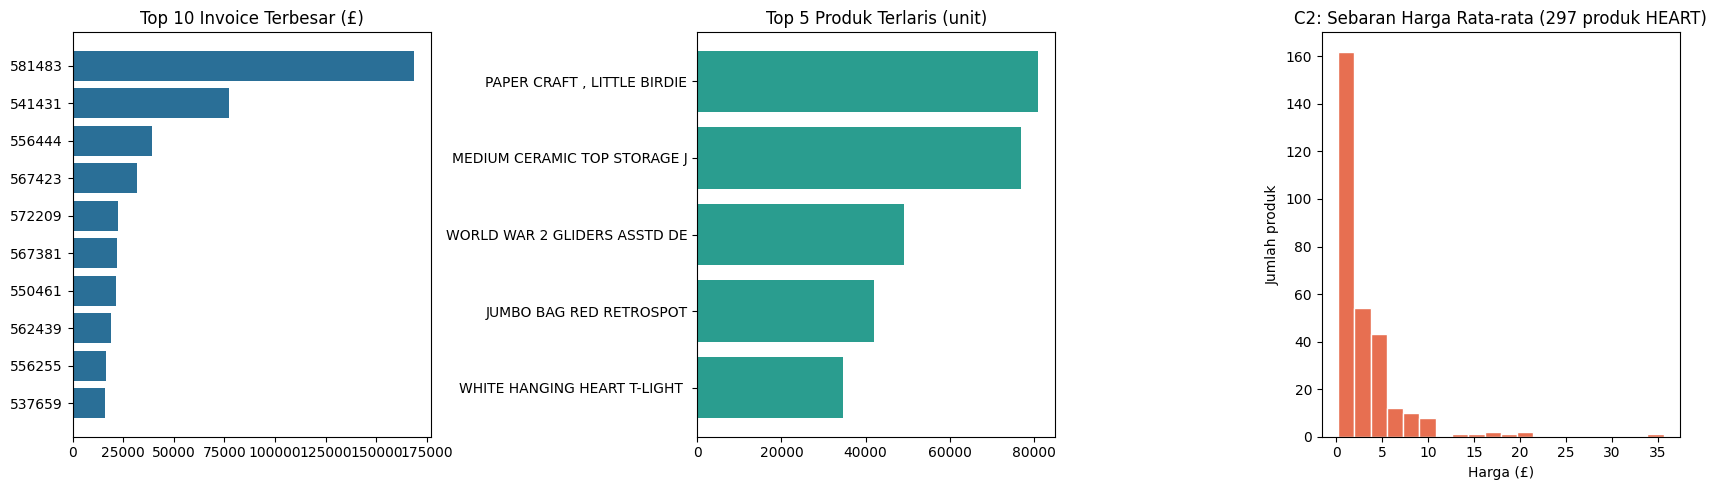

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))

# Top 10 invoice
inv = top_10_invoices[::-1]
ax[0].barh([i for i, _ in inv], [t for _, t in inv], color="#2a6f97")
ax[0].set_title("Top 10 Invoice Terbesar (£)")

# Top 5 produk terlaris
prod = rdd_product_qty.take(5)[::-1]
ax[1].barh([p[:28] for p, _ in prod], [q for _, q in prod], color="#2a9d8f")
ax[1].set_title("Top 5 Produk Terlaris (unit)")

# C2: histogram rata-rata harga produk HEART
prices = rdd_heart_avg.values().collect()
ax[2].hist(prices, bins=20, color="#e76f51", edgecolor="white")
ax[2].set_title(f"C2: Sebaran Harga Rata-rata ({len(prices)} produk HEART)")
ax[2].set_xlabel("Harga (£)"); ax[2].set_ylabel("Jumlah produk")

plt.tight_layout(); plt.show()